# Actividad 4

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, Markdown
from scipy.stats import skew

from sklearn.model_selection import KFold, cross_validate, cross_val_predict
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PowerTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

pd.set_option("display.max_columns", 50)
pd.options.display.float_format = "{:,.3f}".format
RANDOM_STATE = 42

## 1. Carga y descripción del dataset

In [2]:
DATA_PATH = Path("census_income.csv")
df = pd.read_csv(DATA_PATH)

print(f"Filas: {df.shape[0]:,}")
print(f"Columnas: {df.shape[1]}")
display(df.head())

Filas: 10,000
Columnas: 9


,age,hours_per_week,education,employer_type,marital_status,sex,race,born_in_us,income
0,55,55.000,Graduate degree,Self-employed (incorporated),Divorced,Male,White,Yes,"279,000.000"
1,20,35.000,High school,Private,Never married,Female,White,Yes,"23,000.000"
2,59,30.000,High school,State government,Divorced,Female,White,Yes,"15,100.000"
3,43,40.000,Some college,State government,Married,Male,Black,Yes,"31,200.000"
4,33,20.000,No high school diploma,Private,Married,Female,Black,Yes,"9,400.000"


In [3]:
resumen_tipos = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "faltantes": df.isna().sum(),
    "% faltantes": (df.isna().mean() * 100).round(2),
    "n_unicos": df.nunique(dropna=True)
})
display(resumen_tipos)

,dtype,faltantes,% faltantes,n_unicos
age,int64,0,0.000,73
hours_per_week,float64,500,5.000,80
education,object,300,3.000,6
employer_type,object,400,4.000,8
marital_status,object,0,0.000,5
sex,object,0,0.000,2
race,object,0,0.000,4
born_in_us,object,0,0.000,2
income,float64,0,0.000,1365


### Preprocesamiento previsto

Hay faltantes en `hours_per_week`, `education` y `employer_type`. Para evitar leakage:

- variables numéricas: imputación con **mediana** y estandarización;
- variables categóricas: imputación con **moda** y one-hot encoding;
- todo se ajustará dentro del `Pipeline` y por separado en cada fold.

No se hará `fit_transform` sobre la base completa antes de la validación cruzada.

## 2. Parte 1.a — Distribución de la target y target engineering

In [4]:
y = df["income"].copy()

estadisticas_target = pd.Series({
    "mínimo": y.min(),
    "media": y.mean(),
    "mediana": y.median(),
    "percentil 90": y.quantile(0.90),
    "percentil 95": y.quantile(0.95),
    "percentil 99": y.quantile(0.99),
    "máximo": y.max(),
    "skewness": skew(y, bias=False)
}, name="income")

display(estadisticas_target.to_frame())

,income
mínimo,110.000
media,"54,406.827"
mediana,"36,400.000"
percentil 90,"110,000.000"
percentil 95,"150,000.000"
percentil 99,"471,000.000"
máximo,"1,096,000.000"
skewness,4.453


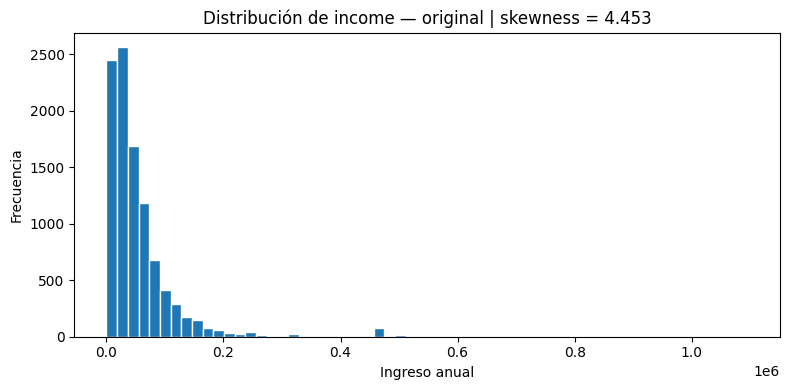

In [5]:
plt.figure(figsize=(8, 4))
plt.hist(y, bins=60, edgecolor="white")
plt.title(f"Distribución de income — original | skewness = {skew(y, bias=False):.3f}")
plt.xlabel("Ingreso anual")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.show()

La target presenta una fuerte **asimetría positiva**: la mayoría de las observaciones está en ingresos bajos/medios y existe una cola larga hacia valores altos.

Como todos los ingresos son mayores que cero, Box-Cox es aplicable. Primero se comparan varias transformaciones de forma descriptiva. El ajuste mostrado aquí **no se reutiliza para entrenar el modelo**; durante cross validation la transformación se vuelve a ajustar únicamente con el train de cada fold.

In [6]:
y_np = y.to_numpy()

y_log = np.log(y_np)

bc_eda = PowerTransformer(method="box-cox", standardize=False)
y_boxcox_eda = bc_eda.fit_transform(y_np.reshape(-1, 1)).ravel()

yj_eda = PowerTransformer(method="yeo-johnson", standardize=False)
y_yj_eda = yj_eda.fit_transform(y_np.reshape(-1, 1)).ravel()

comparacion_transformaciones = pd.DataFrame({
    "Transformación": ["Original", "Log", "Box-Cox", "Yeo-Johnson"],
    "Skewness": [
        skew(y_np, bias=False),
        skew(y_log, bias=False),
        skew(y_boxcox_eda, bias=False),
        skew(y_yj_eda, bias=False)
    ],
    "Lambda": [np.nan, np.nan, bc_eda.lambdas_[0], yj_eda.lambdas_[0]]
})

display(comparacion_transformaciones)

,Transformación,Skewness,Lambda
0,Original,4.453,NaN
1,Log,-1.011,NaN
2,Box-Cox,0.055,0.214
3,Yeo-Johnson,0.055,0.214


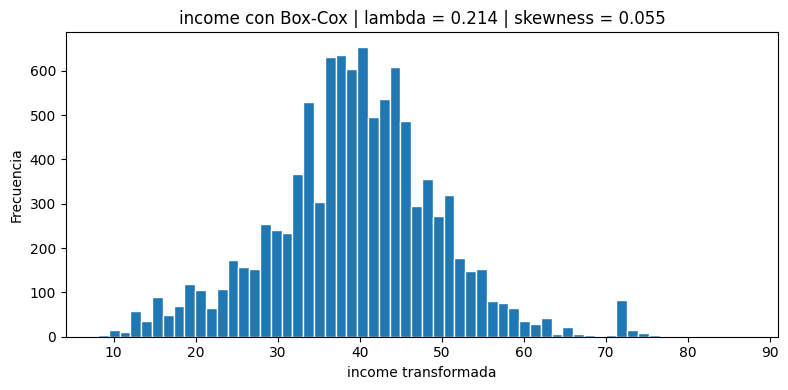

In [7]:
plt.figure(figsize=(8, 4))
plt.hist(y_boxcox_eda, bins=60, edgecolor="white")
plt.title(
    f"income con Box-Cox | lambda = {bc_eda.lambdas_[0]:.3f} | "
    f"skewness = {skew(y_boxcox_eda, bias=False):.3f}"
)
plt.xlabel("income transformada")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.show()

### Elección

Se elige **Box-Cox** porque `income` es estrictamente positiva y esta transformación deja la skewness mucho más cerca de cero que el log. Además, el parámetro lambda se estima automáticamente.

La elección se usará dentro de `TransformedTargetRegressor`, para que lambda se ajuste exclusivamente sobre la target de entrenamiento de cada fold.

## 3. Parte 1.b — Regresión lineal con k-fold cross validation sin data leakage

In [8]:
X = df.drop(columns="income")
y = df["income"]

columnas_numericas = ["age", "hours_per_week"]
columnas_categoricas = [c for c in X.columns if c not in columnas_numericas]

preprocesador = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline(steps=[
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            columnas_numericas
        ),
        (
            "cat",
            Pipeline(steps=[
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore", drop="first"))
            ]),
            columnas_categoricas
        )
    ]
)

modelo_original = Pipeline(steps=[
    ("preprocesador", preprocesador),
    ("regresion", LinearRegression())
])

modelo_boxcox = TransformedTargetRegressor(
    regressor=modelo_original,
    transformer=PowerTransformer(method="box-cox", standardize=False)
)

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print("Variables numéricas:", columnas_numericas)
print("Variables categóricas:", columnas_categoricas)
print("CV:", cv)

Variables numéricas: ['age', 'hours_per_week']
Variables categóricas: ['education', 'employer_type', 'marital_status', 'sex', 'race', 'born_in_us']
CV: KFold(n_splits=5, random_state=42, shuffle=True)


### ¿Por qué no hay leakage?

En cada fold se vuelve a ajustar:

1. la mediana/moda para imputación;
2. la media y desvío del `StandardScaler`;
3. las categorías del `OneHotEncoder`;
4. el lambda de Box-Cox sobre la target.

Es decir, los datos del fold de validación no participan en ningún ajuste previo.

In [9]:
scoring = {
    "MAE": "neg_mean_absolute_error",
    "R2": "r2"
}

cv_original = cross_validate(
    modelo_original,
    X,
    y,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

cv_boxcox = cross_validate(
    modelo_boxcox,
    X,
    y,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_estimator=True
)

tabla_folds = pd.DataFrame({
    "Fold": np.arange(1, 6),
    "MAE original": -cv_original["test_MAE"],
    "MAE Box-Cox": -cv_boxcox["test_MAE"],
    "R2 original": cv_original["test_R2"],
    "R2 Box-Cox": cv_boxcox["test_R2"]
})

display(tabla_folds)

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 776, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 64, in _populate_warmup_workbook
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 38270, in get_range
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 152, in call
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 116, in _recv_one_line
artifact_tool.rpc.client.TransportError: RPC connecti

,Fold,MAE original,MAE Box-Cox,R2 original,R2 Box-Cox
0,1,"30,185.662","27,466.872",0.264,0.228
1,2,"31,570.621","28,454.435",0.229,0.209
2,3,"31,370.636","28,038.173",0.263,0.248
3,4,"30,299.421","26,948.174",0.308,0.285
4,5,"32,095.799","28,842.495",0.271,0.267


In [10]:
resumen_cv = pd.DataFrame({
    "Modelo": ["Target original", "Target Box-Cox"],
    "MAE medio": [
        (-cv_original["test_MAE"]).mean(),
        (-cv_boxcox["test_MAE"]).mean()
    ],
    "Desvío MAE": [
        (-cv_original["test_MAE"]).std(),
        (-cv_boxcox["test_MAE"]).std()
    ],
    "R2 medio": [
        cv_original["test_R2"].mean(),
        cv_boxcox["test_R2"].mean()
    ]
})

mae_original = resumen_cv.loc[0, "MAE medio"]
mae_boxcox = resumen_cv.loc[1, "MAE medio"]
mejora_mae_pct = (mae_original - mae_boxcox) / mae_original * 100

display(resumen_cv)
print(f"Reducción relativa del MAE con Box-Cox: {mejora_mae_pct:.2f}%")

,Modelo,MAE medio,Desvío MAE,R2 medio
0,Target original,"31,104.428",743.396,0.267
1,Target Box-Cox,"27,950.030",677.620,0.247


Reducción relativa del MAE con Box-Cox: 10.14%


In [11]:
lambdas_por_fold = [
    estimador.transformer_.lambdas_[0]
    for estimador in cv_boxcox["estimator"]
]

display(pd.DataFrame({
    "Fold": np.arange(1, 6),
    "Lambda Box-Cox ajustado solo con train": lambdas_por_fold
}))

,Fold,Lambda Box-Cox ajustado solo con train
0,1,0.211
1,2,0.215
2,3,0.213
3,4,0.212
4,5,0.219


Los lambdas no son idénticos entre folds. Eso es evidencia de que la transformación no se estimó una única vez usando toda la base: cada modelo la aprende con su propio conjunto de entrenamiento.

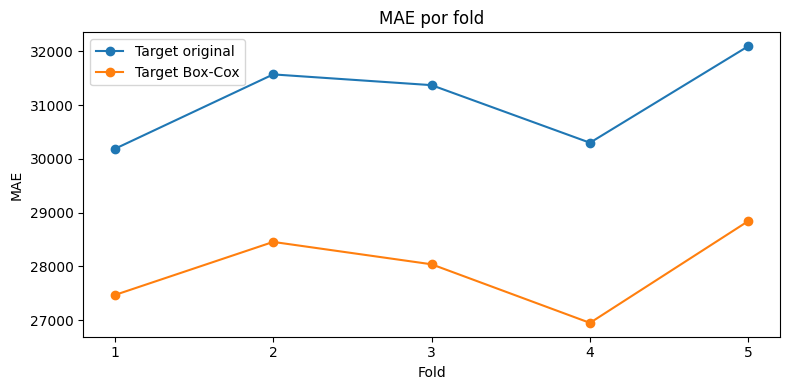

In [12]:
plt.figure(figsize=(8, 4))
plt.plot(tabla_folds["Fold"], tabla_folds["MAE original"], marker="o", label="Target original")
plt.plot(tabla_folds["Fold"], tabla_folds["MAE Box-Cox"], marker="o", label="Target Box-Cox")
plt.title("MAE por fold")
plt.xlabel("Fold")
plt.ylabel("MAE")
plt.xticks(tabla_folds["Fold"])
plt.legend()
plt.tight_layout()
plt.show()

## 4. Parte 1.c — Comparación del MAE y selección del modelo final

`TransformedTargetRegressor` invierte Box-Cox antes de entregar la predicción, por lo que el MAE se calcula en las **unidades originales del ingreso**.

Además se generan predicciones out-of-fold (OOF): cada observación es predicha por un modelo que no fue entrenado con esa observación.

In [13]:
pred_oof_boxcox = cross_val_predict(
    modelo_boxcox,
    X,
    y,
    cv=cv,
    n_jobs=-1
)

mae_oof = mean_absolute_error(y, pred_oof_boxcox)
r2_oof = r2_score(y, pred_oof_boxcox)

print(f"MAE OOF del modelo Box-Cox: {mae_oof:,.2f}")
print(f"R2 OOF del modelo Box-Cox:  {r2_oof:.3f}")

MAE OOF del modelo Box-Cox: 27,950.03
R2 OOF del modelo Box-Cox:  0.247


Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

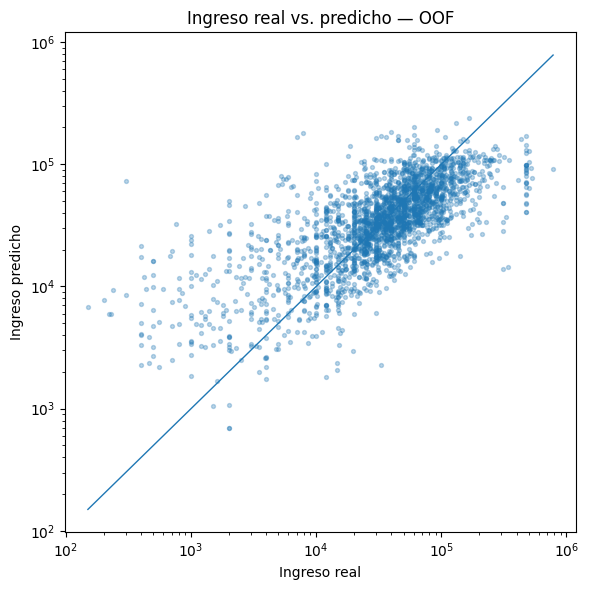

In [14]:
muestra = pd.DataFrame({
    "real": y,
    "predicho": pred_oof_boxcox
}).sample(n=min(2500, len(y)), random_state=RANDOM_STATE)

plt.figure(figsize=(6, 6))
plt.scatter(muestra["real"], muestra["predicho"], s=8, alpha=0.3)
lim_min = max(1, min(muestra["real"].min(), muestra["predicho"].min()))
lim_max = max(muestra["real"].max(), muestra["predicho"].max())
plt.plot([lim_min, lim_max], [lim_min, lim_max], linewidth=1)
plt.xscale("log")
plt.yscale("log")
plt.title("Ingreso real vs. predicho — OOF")
plt.xlabel("Ingreso real")
plt.ylabel("Ingreso predicho")
plt.tight_layout()
plt.show()

In [15]:
texto = f"""
### Conclusión de la Parte 1

- Skewness original: **{skew(y, bias=False):.3f}**.
- Skewness con Box-Cox en el diagnóstico descriptivo: **{skew(y_boxcox_eda, bias=False):.3f}**.
- MAE CV con target original: **${mae_original:,.2f}**.
- MAE CV con target Box-Cox: **${mae_boxcox:,.2f}**.
- Reducción relativa del MAE: **{mejora_mae_pct:.2f}%**.
- Aunque el R² no aumenta, la métrica solicitada por la consigna es MAE y, según ella, Box-Cox es preferible.

Por lo tanto, el modelo final seleccionado es la **regresión lineal con target Box-Cox**.
"""
display(Markdown(texto))


### Conclusión de la Parte 1

- Skewness original: **4.453**.
- Skewness con Box-Cox en el diagnóstico descriptivo: **0.055**.
- MAE CV con target original: **$31,104.43**.
- MAE CV con target Box-Cox: **$27,950.03**.
- Reducción relativa del MAE: **10.14%**.
- Aunque el R² no aumenta, la métrica solicitada por la consigna es MAE y, según ella, Box-Cox es preferible.

Por lo tanto, el modelo final seleccionado es la **regresión lineal con target Box-Cox**.


# 5. Parte 2.a — Auditoría de sesgos

Se auditan `sex` y, adicionalmente, `race`.

Las métricas se calculan sobre predicciones OOF del modelo seleccionado, no sobre predicciones de entrenamiento.

Se reportan:

- tamaño del grupo;
- ingreso medio;
- MAE;
- MAE dividido por el ingreso medio del grupo, como referencia descriptiva de escala;
- error medio firmado (`predicho - real`), donde un valor negativo indica subpredicción.

In [16]:
auditoria = df[["sex", "race", "income"]].copy()
auditoria["predicho"] = pred_oof_boxcox
auditoria["error_abs"] = np.abs(auditoria["predicho"] - auditoria["income"])
auditoria["error_firmado"] = auditoria["predicho"] - auditoria["income"]

def metricas_por_grupo(columna):
    out = auditoria.groupby(columna).agg(
        n=("income", "size"),
        income_medio=("income", "mean"),
        MAE=("error_abs", "mean"),
        error_medio_firmado=("error_firmado", "mean"),
        prediccion_media=("predicho", "mean")
    )
    out["MAE / income medio"] = out["MAE"] / out["income_medio"]
    return out.sort_values("MAE", ascending=False)

metricas_sex = metricas_por_grupo("sex")
metricas_race = metricas_por_grupo("race")

print("Métricas por sex")
display(metricas_sex)

print("Métricas por race")
display(metricas_race)

Métricas por sex


,n,income_medio,MAE,error_medio_firmado,prediccion_media,MAE / income medio
sex,,,,,,
Male,5136,"65,112.781","33,649.330","-12,809.631","52,303.150",0.517
Female,4864,"43,102.185","21,932.019","-7,537.027","35,565.159",0.509


Métricas por race


,n,income_medio,MAE,error_medio_firmado,prediccion_media,MAE / income medio
race,,,,,,
Asian,432,"62,466.065","32,760.123","-12,804.234","49,661.831",0.524
White,6797,"59,973.454","31,078.948","-12,077.241","47,896.212",0.518
Black,2341,"39,688.736","19,618.832","-5,294.651","34,394.085",0.494
Other or multiple,430,"38,446.605","19,015.424","-5,663.134","32,783.470",0.495


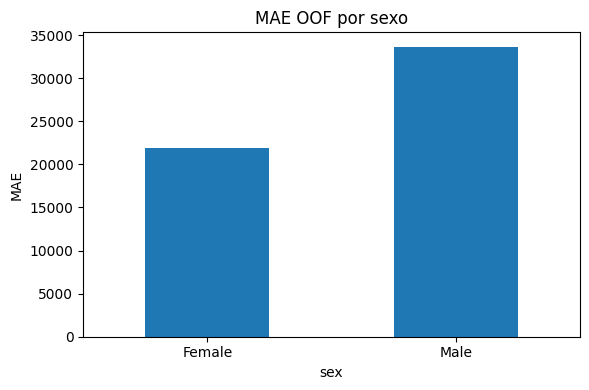

In [17]:
plt.figure(figsize=(6, 4))
metricas_sex["MAE"].sort_values().plot(kind="bar")
plt.title("MAE OOF por sexo")
plt.xlabel("sex")
plt.ylabel("MAE")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

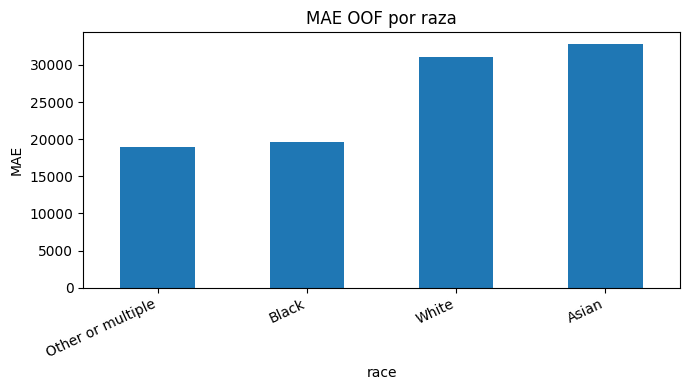

In [18]:
plt.figure(figsize=(7, 4))
metricas_race["MAE"].sort_values().plot(kind="bar")
plt.title("MAE OOF por raza")
plt.xlabel("race")
plt.ylabel("MAE")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

In [19]:
mae_hombre = metricas_sex.loc["Male", "MAE"]
mae_mujer = metricas_sex.loc["Female", "MAE"]
ratio_mae_sex = max(mae_hombre, mae_mujer) / min(mae_hombre, mae_mujer)

texto_auditoria = f"""
### Interpretación

**Sexo**

- MAE en `Male`: **${mae_hombre:,.2f}**.
- MAE en `Female`: **${mae_mujer:,.2f}**.
- El MAE absoluto mayor es aproximadamente **{ratio_mae_sex:.2f} veces** el menor.
- Al dividir por el ingreso medio del grupo, los valores son bastante parecidos:
  **{metricas_sex.loc['Male', 'MAE / income medio']:.1%}** para `Male` y
  **{metricas_sex.loc['Female', 'MAE / income medio']:.1%}** para `Female`.
- El error firmado medio es negativo en ambos grupos: el modelo tiende a **subpredecir** ingresos.

**Raza**

- Los MAE absolutos más altos aparecen en `Asian` y `White`, grupos que también presentan ingresos medios más altos en esta base.
- El MAE relativo al ingreso medio queda aproximadamente en el rango 49%-52%.
- `Asian` y `Other or multiple` tienen muchas menos observaciones que `White`; sus métricas son menos estables.

**Conclusión**

Hay disparidades de error absoluto entre grupos. Sin embargo, parte de la brecha está asociada a la distinta escala de ingreso, porque las diferencias relativas se reducen al contextualizar el MAE con el ingreso medio. Esto no prueba ausencia de sesgo: `sex` y `race` son atributos sensibles incluidos como entradas y la base puede contener sesgos históricos o de muestreo.
"""
display(Markdown(texto_auditoria))


### Interpretación

**Sexo**

- MAE en `Male`: **$33,649.33**.
- MAE en `Female`: **$21,932.02**.
- El MAE absoluto mayor es aproximadamente **1.53 veces** el menor.
- Al dividir por el ingreso medio del grupo, los valores son bastante parecidos:
  **51.7%** para `Male` y
  **50.9%** para `Female`.
- El error firmado medio es negativo en ambos grupos: el modelo tiende a **subpredecir** ingresos.

**Raza**

- Los MAE absolutos más altos aparecen en `Asian` y `White`, grupos que también presentan ingresos medios más altos en esta base.
- El MAE relativo al ingreso medio queda aproximadamente en el rango 49%-52%.
- `Asian` y `Other or multiple` tienen muchas menos observaciones que `White`; sus métricas son menos estables.

**Conclusión**

Hay disparidades de error absoluto entre grupos. Sin embargo, parte de la brecha está asociada a la distinta escala de ingreso, porque las diferencias relativas se reducen al contextualizar el MAE con el ingreso medio. Esto no prueba ausencia de sesgo: `sex` y `race` son atributos sensibles incluidos como entradas y la base puede contener sesgos históricos o de muestreo.


## 6. Entrenamiento del modelo final

Finalizada la evaluación, se ajusta el modelo seleccionado con toda la base. Las métricas reportadas siguen siendo las de CV/OOF, no las de entrenamiento.

In [20]:
modelo_final = modelo_boxcox.fit(X, y)

print("Modelo final entrenado con todas las observaciones.")
print(
    "Lambda Box-Cox final:",
    round(float(modelo_final.transformer_.lambdas_[0]), 4)
)

Modelo final entrenado con todas las observaciones.
Lambda Box-Cox final: 0.2141


Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

# 7. Parte 2.b — Model Card

In [21]:
card_md = f"""
# Model Card — Regresión de ingreso anual

## 1. Detalles del modelo
- **Nombre:** Regresión lineal con target Box-Cox.
- **Versión:** 1.0.
- **Modelo:** `LinearRegression` dentro de un pipeline de scikit-learn.
- **Target engineering:** Box-Cox mediante `TransformedTargetRegressor`.
- **Validación:** KFold de 5 folds con shuffle y semilla {RANDOM_STATE}.

## 2. Propósito
Estimar `income` anual a partir de variables demográficas y laborales para fines académicos.

**No usar como único criterio para decisiones de crédito, contratación, salarios, seguros u otras decisiones de alto impacto.**

## 3. Entradas
`age`, `hours_per_week`, `education`, `employer_type`, `marital_status`, `sex`, `race`, `born_in_us`.

## 4. Salida
Ingreso anual estimado en las mismas unidades monetarias de `income`.

## 5. Prevención de leakage
- Imputación numérica por mediana.
- Estandarización con `StandardScaler`.
- Imputación categórica por moda.
- One-hot encoding.
- Todos los pasos se ajustan dentro de cada fold.
- Box-Cox se ajusta sobre la target de entrenamiento de cada fold.

## 6. Métricas globales
- **MAE CV target original:** ${mae_original:,.2f}
- **MAE CV target Box-Cox:** ${mae_boxcox:,.2f}
- **Mejora relativa del MAE:** {mejora_mae_pct:.2f}%
- **MAE OOF modelo final:** ${mae_oof:,.2f}
- **R² OOF:** {r2_oof:.3f}

## 7. Métricas por sexo
- **Male:** MAE = ${metricas_sex.loc['Male','MAE']:,.2f}; MAE/ingreso medio = {metricas_sex.loc['Male','MAE / income medio']:.1%}; n = {int(metricas_sex.loc['Male','n']):,}
- **Female:** MAE = ${metricas_sex.loc['Female','MAE']:,.2f}; MAE/ingreso medio = {metricas_sex.loc['Female','MAE / income medio']:.1%}; n = {int(metricas_sex.loc['Female','n']):,}

## 8. Métricas adicionales por raza
- **White:** MAE = ${metricas_race.loc['White','MAE']:,.2f}; n = {int(metricas_race.loc['White','n']):,}
- **Black:** MAE = ${metricas_race.loc['Black','MAE']:,.2f}; n = {int(metricas_race.loc['Black','n']):,}
- **Asian:** MAE = ${metricas_race.loc['Asian','MAE']:,.2f}; n = {int(metricas_race.loc['Asian','n']):,}
- **Other or multiple:** MAE = ${metricas_race.loc['Other or multiple','MAE']:,.2f}; n = {int(metricas_race.loc['Other or multiple','n']):,}

## 9. Limitaciones y riesgos
- La regresión lineal impone una estructura simple.
- La target tiene una cola extrema y persisten errores altos en dólares.
- `sex` y `race` son atributos sensibles incluidos como entradas.
- Las diferencias de MAE por grupo no prueban causalidad ni discriminación por sí solas.
- Los subgrupos raciales pequeños producen estimaciones menos estables.
- La base puede reflejar sesgos históricos o de muestreo.
- No se evaluó desempeño fuera de la población representada por este dataset.

## 10. Monitoreo recomendado
Monitorear MAE global, MAE por subgrupos, drift de variables, cambios en la distribución de `income` y estabilidad de la transformación.
"""

display(Markdown(card_md))
Path("MODEL_CARD_Actividad4.md").write_text(card_md, encoding="utf-8")
print("Model Card guardada en MODEL_CARD_Actividad4.md")


# Model Card — Regresión de ingreso anual

## 1. Detalles del modelo
- **Nombre:** Regresión lineal con target Box-Cox.
- **Versión:** 1.0.
- **Modelo:** `LinearRegression` dentro de un pipeline de scikit-learn.
- **Target engineering:** Box-Cox mediante `TransformedTargetRegressor`.
- **Validación:** KFold de 5 folds con shuffle y semilla 42.

## 2. Propósito
Estimar `income` anual a partir de variables demográficas y laborales para fines académicos.

**No usar como único criterio para decisiones de crédito, contratación, salarios, seguros u otras decisiones de alto impacto.**

## 3. Entradas
`age`, `hours_per_week`, `education`, `employer_type`, `marital_status`, `sex`, `race`, `born_in_us`.

## 4. Salida
Ingreso anual estimado en las mismas unidades monetarias de `income`.

## 5. Prevención de leakage
- Imputación numérica por mediana.
- Estandarización con `StandardScaler`.
- Imputación categórica por moda.
- One-hot encoding.
- Todos los pasos se ajustan dentro de cada fold.
- Box-Cox se ajusta sobre la target de entrenamiento de cada fold.

## 6. Métricas globales
- **MAE CV target original:** $31,104.43
- **MAE CV target Box-Cox:** $27,950.03
- **Mejora relativa del MAE:** 10.14%
- **MAE OOF modelo final:** $27,950.03
- **R² OOF:** 0.247

## 7. Métricas por sexo
- **Male:** MAE = $33,649.33; MAE/ingreso medio = 51.7%; n = 5,136
- **Female:** MAE = $21,932.02; MAE/ingreso medio = 50.9%; n = 4,864

## 8. Métricas adicionales por raza
- **White:** MAE = $31,078.95; n = 6,797
- **Black:** MAE = $19,618.83; n = 2,341
- **Asian:** MAE = $32,760.12; n = 432
- **Other or multiple:** MAE = $19,015.42; n = 430

## 9. Limitaciones y riesgos
- La regresión lineal impone una estructura simple.
- La target tiene una cola extrema y persisten errores altos en dólares.
- `sex` y `race` son atributos sensibles incluidos como entradas.
- Las diferencias de MAE por grupo no prueban causalidad ni discriminación por sí solas.
- Los subgrupos raciales pequeños producen estimaciones menos estables.
- La base puede reflejar sesgos históricos o de muestreo.
- No se evaluó desempeño fuera de la población representada por este dataset.

## 10. Monitoreo recomendado
Monitorear MAE global, MAE por subgrupos, drift de variables, cambios en la distribución de `income` y estabilidad de la transformación.


Model Card guardada en MODEL_CARD_Actividad4.md
